# Count on me? Reproducibility notebook

This notebook produces every table, figure and computed number of *Count on Me? A Replication of "Social Ties in Academia: A Friend Is a Treasure"* (Huynh, Jacho-Chávez and Sánchez-Aragón). It is the main file of the repository `count_on_me`.

It follows the paper section by section, so it can be read side by side with the PDF. Each table and figure is written to `output/` at the point where the paper shows it, and the same table is shown here in HTML. Each number that the text computes from the data is printed next to the number written in the paper, and the last section lists any number that does not match.

| Paper | Notebook section | Output |
|:---|:---|:---|
| 1. Introduction and abstract | checked in 6 | |
| 2. The original study | checked in 3.1 | |
| 3. Data and narrow replication | 3 | `tables/tab_descriptives.tex` (Table 1) |
| 4. Poisson pseudo-maximum likelihood estimation | 4 | `figures/fig_zeros.tex` (Figure 1) |
| 5. Results | 5 | `tables/tab_ppml_table3.tex` (Table 2), `tables/tab_comparison.tex` (Table 3) |
| 6. Conclusion | 6 | |
| Appendix A | A | `tables/tab_corrections.tex` (Table A-3) |
| Appendix B | B | `tables/tab_table3_reghdfe_extended.tex` (Table B-1) |
| Appendix C | C | `tables/tab_python.tex` (Table C-1) |

Data. `data/original/` holds Colussi's replication files. `data/corrected/` holds the same files after the 35 corrections of the narrow replication; Section 3.4 adds the consistency fixes of Appendix A, Stage 4, and saves version 2 of the corrected data in the same folder. Colussi's code is applied unchanged to both.

Requirements. Stata 17 or later with `require`, `ftools`, `reghdfe` and `ppmlhdfe` (installed from SSC if missing), and Python 3.11 or later with the packages in `requirements.txt`. A full run takes a few minutes.

## 0. Set-up

In [1]:
%%capture output
import platform, sys, os

def _pystata_fallback(path, edition):
    sys.path.append(os.path.join(path, 'utilities'))
    from pystata import config
    config.init(edition, splash=False)

_CANDIDATES = [("C:/Program Files/StataNow19", "se"), ("C:/Program Files/Stata19", "se"),
               ("C:/Program Files/Stata18", "se"), ("C:/Program Files/Stata17", "mp"),
               ("/Applications/Stata", "mp"), ("/usr/local/stata17", "mp")]
try:
    import stata_setup
    for _path, _ed in _CANDIDATES:
        if os.path.exists(_path):
            stata_setup.config(_path, _ed)
            break
except ImportError:
    for _path, _ed in _CANDIDATES:
        if os.path.exists(_path):
            _pystata_fallback(_path, _ed)
            break

In [2]:
from pystata import stata
from sfi import Scalar
stata.run('macro drop _all')
stata.run('set more off')
# reghdfe 6 needs the require package; install every dependency that is missing
for _pkg in ['require', 'ftools', 'reghdfe', 'ppmlhdfe']:
    stata.run(f'cap which {_pkg}\nif _rc ssc install {_pkg}, replace', quietly=True)
stata.run('cap which require\nscalar __req = _rc', quietly=True)
assert Scalar.getValue('__req') == 0, 'require is not installed: run  ssc install require, replace  in Stata'
stata.run('which require\nwhich reghdfe\nwhich ppmlhdfe')

# Python replication (Appendix C) uses fasthdfe
try:
    import fasthdfe
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'fasthdfe'])
    import fasthdfe

(-set more- irrelevant in this version of Stata)






. which require
C:\Users\leona\ado\plus\r\require.ado
*! version 1.3.1 19sep2023

. which reghdfe
C:\Users\leona\ado\plus\r\reghdfe.ado
*! version 6.13.1 10Jan2026

. which ppmlhdfe
C:\Users\leona\ado\plus\p\ppmlhdfe.ado
*! version 2.3.0 25feb2021
*! Authors: Sergio Correia, Paulo Guimarães, Thomas Zylkin
*! URL: https://github.com/sergiocorreia/ppmlhdfe

. 


### Directories

`ROOT` is the folder of this notebook, the root of the repository. Tables, Figure 1 and CSV files go to `output/`. If you also keep the paper's Overleaf folder on your computer, add it below and every table and figure is written there too.

In [3]:
import getpass
from pathlib import Path

ROOT     = Path.cwd().resolve()
DTA_ORIG = ROOT / 'data' / 'original'
DTA_UPD  = ROOT / 'data' / 'corrected'
OUT      = ROOT / 'output'

# optional: the Overleaf folder of the paper (Dropbox sync), per user
OVERLEAF = {'leona':   Path('C:/Users/leona/Dropbox/Apps/Overleaf/Colussi_PPML'),
            'djachoc': Path('C:/Users/djachoc/Dropbox/Apps/Overleaf/Colussi_PPML')}.get(getpass.getuser().lower(), Path('__none__'))

TEX_DIRS = [OUT / 'tables'] + ([OVERLEAF / 'tables'] if OVERLEAF.exists() else [])
FIG_DIRS = [OUT / 'figures'] + ([OVERLEAF / 'figures'] if OVERLEAF.exists() else [])
CSV_OUT  = OUT / 'csv'
for p in TEX_DIRS + FIG_DIRS + [CSV_OUT]:
    p.mkdir(parents=True, exist_ok=True)
assert (DTA_ORIG / 'TOREG.dta').exists() and (DTA_UPD / 'TOREG_UPDATED.dta').exists(), 'data not found: run the notebook from the repository folder'

def s(p):
    return str(p).replace('\\', '/')

print('repository :', ROOT)
print('tables to  :', *TEX_DIRS)
print('figures to :', *FIG_DIRS)

repository : C:\Users\leona\OneDrive\res\Net_journals\Replication_Colussi\count_on_me
tables to  : C:\Users\leona\OneDrive\res\Net_journals\Replication_Colussi\count_on_me\output\tables C:\Users\leona\Dropbox\Apps\Overleaf\Colussi_PPML\tables
figures to : C:\Users\leona\OneDrive\res\Net_journals\Replication_Colussi\count_on_me\output\figures C:\Users\leona\Dropbox\Apps\Overleaf\Colussi_PPML\figures


### Helper functions

The functions that compute Colussi's Table 1 and write the tables and Figure 1 are in `count_on_me_tables.py`, next to this notebook. This cell imports them and defines three helpers: `est()` runs one Stata estimation and returns the `Incharge` coefficient, standard error, $p$-value, observations and editors; `check()` compares a number of the paper with the notebook; `write_table()` writes a table to Overleaf and shows it here.

In [4]:
import numpy as np, pandas as pd
from IPython.display import display, HTML
sys.path.insert(0, str(Path.cwd()))
from count_on_me_tables import *      # table, figure and HTML functions, in count_on_me_tables.py next to this notebook
import contextlib, io
if not hasattr(stata, '_run_original'):      # keep the original only once, so the cell can be run twice
    stata._run_original = stata.run
_stata_run = stata._run_original
def _quiet_run(cmd, quietly=False, **kw):
    '''Stata runs with quietly=True print nothing at all (pystata otherwise leaves blank lines).'''
    if quietly:
        with contextlib.redirect_stdout(io.StringIO()):
            return _stata_run(cmd, quietly=True, **kw)
    return _stata_run(cmd, quietly=quietly, **kw)
stata.run = _quiet_run

def _sc(name):
    v = Scalar.getValue(name)
    return None if v is None or v > 8.9e307 else v

def est(cmd, z=False):
    '''Run a Stata estimation; return b, se, p, N and editors for incharge.
    z=True uses the normal distribution (ppmlhdfe), otherwise t with e(df_r) (reghdfe).'''
    stata.run(cmd, quietly=True)
    pexpr = '2*normal(-abs(__b/__se))' if z else '2*ttail(e(df_r), abs(__b/__se))'
    stata.run(f'''scalar __b  = _b[incharge]
scalar __se = _se[incharge]
scalar __N  = e(N)
scalar __p  = {pexpr}
tempvar tag
quietly egen `tag' = tag(namejournal_fe) if e(sample)
quietly count if `tag' == 1
scalar __ed = r(N)''', quietly=True)
    return dict(b=_sc('__b'), se=_sc('__se'), p=_sc('__p'), N=_sc('__N'), editors=_sc('__ed'))

# Numbers in the text of the paper: each one is printed next to the value computed here
CHECKS = []
def check(section, what, paper, notebook, ok=None):
    '''paper: the number as written in the paper; notebook: the same number formatted from the data.'''
    CHECKS.append(dict(section=section, number=what, paper=paper, notebook=notebook,
                       ok=(paper == notebook) if ok is None else bool(ok)))

CHECK_TITLES = {'2': 'Section 2 of the paper', '3': 'Section 3 of the paper', '4': 'Section 4 of the paper',
                '5': 'Section 5 of the paper', '6': 'the abstract, introduction and conclusion',
                'A': 'Appendix A', 'C': 'Appendix C'}
COLS = {'number': 'Number', 'paper': 'Written in the paper', 'notebook': 'Computed here', 'ok': 'Match'}

def show_checks(section, hide=()):
    df = pd.DataFrame([c for c in CHECKS if c['section'] == section and c['number'] not in hide]).drop(columns='section')
    df['ok'] = df['ok'].map({True: 'yes', False: 'NO'})
    display(HTML(f'<p style="font-family:serif;font-size:14px;margin:12px 0 4px 0"><i>Numbers in {CHECK_TITLES[section]}, '
                 f'recomputed from the data</i></p>' + df.rename(columns=COLS).to_html(index=False, border=1)))
    if (df['ok'] == 'NO').any():
        print('Some numbers in the paper differ from the notebook: see the rows marked NO.')

f0 = lambda x: f'{x:.0f}'
f1 = lambda x: f'{x:.1f}'
f2 = lambda x: f'{x:.2f}'
f3 = lambda x: f'{x:.3f}'
f4 = lambda x: f'{x:.4f}'
fc = lambda x: f'{int(round(x)):,}'
fp = lambda p: '<0.001' if p < 0.001 else f'{p:.3f}'

def write_table(name, tex):
    '''Write a LaTeX table to output/tables (and Overleaf, if set) and show the same table here in HTML.'''
    for d in TEX_DIRS:
        (d / name).write_text(tex, encoding='utf-8')
    display(HTML(tex_to_html(tex)))
    print('written:', ', '.join(str(d / name) for d in TEX_DIRS))



## 1. Introduction and abstract

The abstract and the introduction summarize numbers computed in Sections 3 to 5. They are checked in Section 6, together with the conclusion. Section 2 of the paper describes Colussi's study and produces no new result; the numbers it quotes are checked in Section 3.1.

## 3. Data and narrow replication

### 3.1 Narrow replication: Colussi's Table 3 on his files

Colussi estimates

$$y_{ijt} = \beta\,\text{Incharge}_{ijt} + \lambda_{ij} + \zeta_{jt} + u_{ijt}$$

by OLS with editor by journal (`namejournal_fe`) and journal by term (`issue_fe`) fixed effects, and standard errors clustered by journal and term. The cell runs his 18 regressions on his own files and stops if any coefficient differs from his published Table 3 at the fourth decimal. These are the estimates of column (1) of Table 3 in our paper. The cell also checks the numbers that Section 2 of the paper quotes from his study: the size of the panel and his percentage reading of the Ph.D. Advisor and Same Faculty coefficients.

In [5]:
toreg_orig = pd.read_stata(DTA_ORIG / 'TOREG.dta')
check('2', 'Editor identifiers', '42', str(toreg_orig.namejournal_fe.nunique()))
check('2', 'Half-year terms', '14', str(len(toreg_orig[['year', 'term']].drop_duplicates())))
check('2', 'Editor by journal by term cells', '588', str(len(toreg_orig)))
check('2', 'Clusters (journal by term)', '56', str(toreg_orig.issue_fe.nunique()))

ols, ybar = {}, {}
stata.run(f'use "{s(DTA_ORIG / 'TOREG.dta')}", clear', quietly=True)
for o, _ in OUTS:
    for t in TIES:
        y = depvar(o, t)
        ols[('orig', o, t)] = est(f'reghdfe {y} incharge, a(issue_fe namejournal_fe) vce(cluster issue_fe)')
        ybar[('orig', o, t)] = toreg_orig[y].mean()

published_t3 = {'n':    [0.2419, 0.2670, 0.1456, -0.0570, 0.0463, 0.0704],
                'page': [10.9883, 10.2054, 6.0008, -1.3440, 2.7016, 4.6627],
                'lead': [0.0714, 0.0921, -0.0098, -0.0075, 0.0315, -0.0199]}
for o, _ in OUTS:
    for k, t in enumerate(TIES):
        assert abs(round(ols[('orig', o, t)]['b'], 4) - published_t3[o][k]) < 1e-4, ('orig', o, t)
print('OLS reproduces every coefficient of Colussi (2018) Table 3 to the fourth decimal.')

b_adv, m_adv = ols[('orig', 'n', 'Tconn_advisor')]['b'], ybar[('orig', 'n', 'Tconn_advisor')]
b_fac, m_fac = ols[('orig', 'n', 'Tconn_ever')]['b'], ybar[('orig', 'n', 'Tconn_ever')]
check('2', 'Ph.D. Advisor coefficient, articles', '0.1456', f4(b_adv))
check('2', 'Ph.D. Advisor mean, articles', '1.05', f2(m_adv))
check('2', 'Ph.D. Advisor effect (%)', '14', f0(100 * b_adv / m_adv))
check('2', 'Same Faculty coefficient, articles', '0.2670', f4(b_fac))
check('2', 'Same Faculty mean, articles', '3.28', f2(m_fac))
check('2', 'Same Faculty effect (%)', '8', f0(100 * b_fac / m_fac))
show_checks('2', hide=('Editor identifiers', 'Half-year terms', 'Editor by journal by term cells', 'Clusters (journal by term)'))

OLS reproduces every coefficient of Colussi (2018) Table 3 to the fourth decimal.


Number,Written in the paper,Computed here,Match
"Ph.D. Advisor coefficient, articles",0.1456,0.1456,yes
"Ph.D. Advisor mean, articles",1.05,1.05,yes
Ph.D. Advisor effect (%),14,14,yes
"Same Faculty coefficient, articles",0.2670,0.2670,yes
"Same Faculty mean, articles",3.28,3.28,yes
Same Faculty effect (%),8,8,yes


### 3.2 The original files

`ARTICLES.dta` has one row per article and author; `AUTHORS.dta` has one row per author and year.

In [6]:
art_o = pd.read_stata(DTA_ORIG / 'ARTICLES.dta');  art_c = pd.read_stata(DTA_UPD / 'ARTICLES_UPDATED.dta')
aut_o = pd.read_stata(DTA_ORIG / 'AUTHORS.dta');   aut_c = pd.read_stata(DTA_UPD / 'AUTHORS_UPDATED.dta')
check('3', 'Articles, original', '1,620', fc(art_o.articletitle.nunique()))
check('3', 'Distinct authors, original', '2,015', fc(art_o.author.nunique()))
check('3', 'Authors with career records, original', '1,882', fc(aut_o.author.nunique()))
show_checks('3')

Number,Written in the paper,Computed here,Match
"Articles, original","1,620","1,620",yes
"Distinct authors, original","2,015","2,015",yes
"Authors with career records, original","1,882","1,882",yes


### 3.3 The 35 corrections

`article_corrections()` compares the two article files record by record. It returns the recovered articles, the systematic renumbering of AER issues 2 to 4, and the individual corrections listed in Table A-3. New authors are those of `AUTHORS_UPDATED.dta` that are not in `AUTHORS.dta`.

In [7]:
new_art, aer_shift, indiv = article_corrections(DTA_ORIG / 'ARTICLES.dta', DTA_UPD / 'ARTICLES_UPDATED.dta')
new_aut = sorted(set(aut_c.author) - set(aut_o.author))
n_issue = int(((indiv.issue != indiv.issue_u) | (indiv.year != indiv.year_u)).sum())
n_page  = len(indiv) - n_issue
display(HTML(new_art.reset_index().to_html(index=False, border=1)))
check('3', 'Missing articles', '8', str(len(new_art)))
check('3', 'Missing authors', '8', str(len(new_aut)))
check('3', 'Bibliographic corrections', '19', str(len(indiv)))
check('3', 'Errors and omissions in total', '35', str(len(new_art) + len(new_aut) + len(indiv)))
check('3', 'Articles, corrected', '1,628', fc(art_c.articletitle.nunique()))
show_checks('3')

articletitle,year,journal,issue,first_page,last_page
1622.0,2000,AER,3,605,620
1626.0,2005,AER,1,450,460
1624.0,2003,ECA,1,399,407
1625.0,2005,ECA,5,1525,1550
1621.0,2003,JPE,6,1353,1360
1627.0,2006,JPE,3,594,605
1628.0,2006,QJE,1,1,30
1623.0,2006,QJE,4,1347,1381


Number,Written in the paper,Computed here,Match
"Articles, original","1,620","1,620",yes
"Distinct authors, original","2,015","2,015",yes
"Authors with career records, original","1,882","1,882",yes
Missing articles,8,8,yes
Missing authors,8,8,yes
Bibliographic corrections,19,19,yes
Errors and omissions in total,35,35,yes
"Articles, corrected","1,628","1,628",yes


### 3.4 Build the corrected data, version 2 (details in Appendix A)

Our earlier corrections left two inconsistencies, documented in Appendix A, Stage 4: four articles kept the half-year term of their old issue, and one of them (Serrano and Vohra, ECA 2001) kept the editor flags of its old issue. This cell fixes them and saves `FINAL_SAMPLE_UPDATED_v2.dta` and `TOREG_UPDATED_v2.dta`, which all corrected estimates use.

It works in three steps, all checked: it rebuilds `TOREG_UPDATED.dta` from `FINAL_SAMPLE_UPDATED.dta` with the steps of Colussi's `PREPARE.do` and confirms the result is identical; it sets the term of the four articles to the first and gives Serrano and Vohra the editor flags of issue 3; and it rebuilds the panel. Appendix A.3 of this notebook shows each fix.

In [8]:
TV = 'Tconn_phd Tconn_advisor Tconn_ever Tconn_author Tconn_pool key_jel_ref'
prepare = f'''
keep name journal year term issue first_page last_page incharge {TV}
gen double n_page = last_page - first_page
foreach x in {TV} {{
    bys name journal year term: egen double n_`x' = total(`x')
    bys name journal year term: egen double page_`x' = total(n_page * (`x' == 1))
}}
bys year journal issue: egen double min_page = min(first_page)
gen byte lead = (first_page == min_page & min_page < .)
foreach x in {TV} {{
    bys name journal year term: egen double lead_`x' = total(lead * (`x' == 1))
}}
collapse (max) incharge n_* lead_* page_*, by(name journal year term)
drop n_page
egen issue_fe = group(journal year term)
egen namejournal_fe = group(name journal)
sort name journal year term
order name year term journal incharge n_* lead_* page_* issue_fe namejournal_fe
'''
fs1, to1, fs2, to2 = [s(DTA_UPD / x) for x in ('FINAL_SAMPLE_UPDATED.dta', 'TOREG_UPDATED.dta',
                                               'FINAL_SAMPLE_UPDATED_v2.dta', 'TOREG_UPDATED_v2.dta')]

# step 1: the builder reproduces TOREG_UPDATED exactly
stata.run(f'''
use "{to1}", clear
tempfile ref
foreach v of varlist incharge n_* lead_* page_* issue_fe namejournal_fe {{
    rename `v' r_`v'
}}
save `ref'
use "{fs1}", clear
{prepare}
merge 1:1 name journal year term using `ref', assert(match) nogen
foreach v of varlist incharge n_* lead_* page_* issue_fe namejournal_fe {{
    assert `v' == r_`v'
}}
''', quietly=True)

# step 2: fix the term of the four articles and the editor flags of Serrano and Vohra
stata.run(f'''
use "{fs1}", clear
gen byte fix_term = (journal == "ECA" & year == 2001 & first_page == 785) ///
    | (journal == "AER" & year == 2003 & inlist(first_page, 241, 256)) ///
    | (journal == "AER" & year == 2000 & first_page == 605)
gen byte t_rule = cond(journal == "AER", 1 + (issue >= 4), cond(journal == "QJE", 1 + (issue >= 3), 1 + (issue >= 4)))
replace term = 1 if fix_term
assert term == t_rule
replace incharge = 1 if journal == "ECA" & year == 2001 & first_page == 785 & famname == "BLUNDELL"
replace incharge = 0 if journal == "ECA" & year == 2001 & first_page == 785 & famname == "MEGHIR"
bys name journal year issue (incharge): assert incharge[1] == incharge[_N]
drop fix_term t_rule
save "{fs2}", replace
''', quietly=True)

# step 3: rebuild and save the panel
stata.run(f'''
{prepare}
label data "Colussi TOREG, corrected data v2 (term and editor flags fixed)"
save "{to2}", replace
''', quietly=True)

v1, v2 = pd.read_stata(DTA_UPD / 'TOREG_UPDATED.dta'), pd.read_stata(DTA_UPD / 'TOREG_UPDATED_v2.dta')
KEYS = ['name', 'journal', 'year', 'term']
vals = [c for c in v1.columns if c not in KEYS]
m = v1.merge(v2, on=KEYS, suffixes=('', '_v2'))
changed = (m[vals].values != m[[c + '_v2' for c in vals]].values).any(axis=1)
assert len(m) == 588 and (m.incharge == m.incharge_v2).all() and changed.sum() == 8
print('Saved FINAL_SAMPLE_UPDATED_v2.dta and TOREG_UPDATED_v2.dta.')

Saved FINAL_SAMPLE_UPDATED_v2.dta and TOREG_UPDATED_v2.dta.


### 3.5 Table 1: Colussi's Table 1 on the original and corrected data

`colussi_table1()` follows `TABLE1.do` line by line. An article is connected if at least one author has the tie with an editor in charge at publication, and pages are last minus first page. The cell stops if the original columns differ from the published table, and writes Table 1 of the paper.

In [9]:
t1_orig = colussi_table1(DTA_ORIG / 'FINAL_SAMPLE.dta', DTA_ORIG / 'ARTICLES.dta', DTA_ORIG / 'AUTHORS.dta')
t1_corr = colussi_table1(DTA_UPD / 'FINAL_SAMPLE_UPDATED_v2.dta', DTA_UPD / 'ARTICLES_UPDATED.dta', DTA_UPD / 'AUTHORS_UPDATED.dta')

# published Table 1 (Colussi 2018, p. 46)
published = {('Articles', 'All'): 1620, ('Pages', 'All'): 25.92, ('Citations (8 years)', 'All'): 57.69,
             ('Authors', 'All'): 1.95, ('Single author (\\%)', 'All'): 29.32,
             ('References: same journal (\\%)', 'All'): 10.8, ('References: editor cited (\\%)', 'All'): 47.47,
             ('Connected: Same Ph.D.', 'All'): 10.25, ('Connected: Ph.D. Advisor', 'All'): 14.75,
             ('Connected: Same Faculty', 'All'): 28.83, ('Connected: Co-author', 'All'): 7.65,
             ('Connected: Pooled', 'All'): 42.72, ('Articles', 'AER'): 603, ('Articles', 'QJE'): 282,
             ('Pages', 'QJE'): 36.78, ('References: number', 'All'): 32.95, ('References: number', 'AER'): 32.05}
for (r, c), v in published.items():
    assert abs(t1_orig.loc[r, c] - v) < 0.006, (r, c, t1_orig.loc[r, c], v)
print('Table 1 reproduced: all checked cells match the published table.')

both = pd.concat({'Original': t1_orig, 'Corrected': t1_corr}, axis=1).swaplevel(axis=1)[['All'] + JOURNALS]
write_table('tab_descriptives.tex', tex_descriptives(t1_orig, t1_corr))
both.to_csv(CSV_OUT / 'descriptives.csv')

ties_rows = [r for r in t1_orig.index if r.startswith('Connected: ')]
max_change = (t1_corr.loc[ties_rows, 'All'] - t1_orig.loc[ties_rows, 'All']).abs().max()
check('3', 'QJE pages, published as references', '36.78', f2(t1_orig.loc['Pages', 'QJE']))
check('3', 'QJE references in the data', '41.60', f2(t1_orig.loc['References: number', 'QJE']))
check('3', 'Connected share, original (%)', '42.7', f1(t1_orig.loc['Connected: Pooled', 'All']))
check('3', 'Connected share, corrected (%)', '42.6', f1(t1_corr.loc['Connected: Pooled', 'All']))
check('3', 'Largest change in a tie share (pp)', 'less than 0.4', f2(max_change), ok=max_change < 0.4)
show_checks('3')

Table 1 reproduced: all checked cells match the published table.


written: C:\Users\leona\OneDrive\res\Net_journals\Replication_Colussi\count_on_me\output\tables\tab_descriptives.tex, C:\Users\leona\Dropbox\Apps\Overleaf\Colussi_PPML\tables\tab_descriptives.tex


Number,Written in the paper,Computed here,Match
"Articles, original","1,620","1,620",yes
"Distinct authors, original","2,015","2,015",yes
"Authors with career records, original","1,882","1,882",yes
Missing articles,8,8,yes
Missing authors,8,8,yes
Bibliographic corrections,19,19,yes
Errors and omissions in total,35,35,yes
"Articles, corrected","1,628","1,628",yes
"QJE pages, published as references",36.78,36.78,yes
QJE references in the data,41.60,41.60,yes


## 4. Estimation

### 4.1 Figure 1: zeros in the outcomes

The figure shows, for each tie, the share of the 588 cells of the corrected data with 0, 1, 2 and more tied articles (top row) and tied lead articles (bottom row). The paper draws it with pgfplots from `figures/fig_zeros.tex`, written by this cell; the cell also shows a preview.

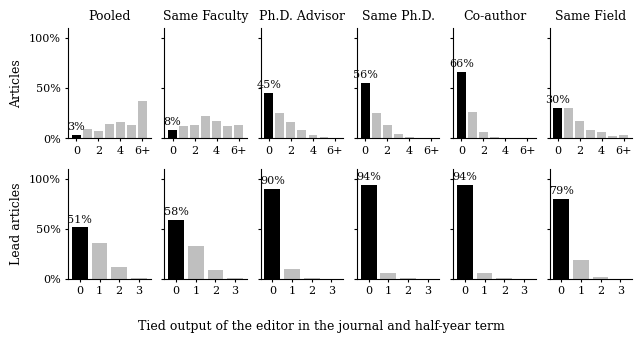

Number,Written in the paper,Computed here,Match
"Zero share, articles, Pooled (%)",3,3,yes
"Zero share, articles, Same Faculty (%)",8,8,yes
"Zero share, articles, Ph.D. Advisor (%)",45,45,yes
"Zero share, articles, Same Ph.D. (%)",56,56,yes
"Zero share, articles, Co-author (%)",66,66,yes
"Zero share, lead articles, lowest (%)",51,51,yes
"Zero share, lead articles, highest (%)",94,94,yes


In [10]:
toreg_v2 = pd.read_stata(DTA_UPD / 'TOREG_UPDATED_v2.dta')
for d in FIG_DIRS:
    fig_zeros_tikz(toreg_v2, d / 'fig_zeros.tex')
from IPython.display import Image
fig_zeros(toreg_v2, CSV_OUT / 'fig_zeros.png')
display(Image(filename=str(CSV_OUT / 'fig_zeros.png')))

zeros = pd.DataFrame({ol: [(toreg_v2[depvar(o, t)] == 0).mean() * 100 for t in TIES] for o, ol in OUTS}, index=TIES)
za, zl = zeros['Number of articles'], zeros['Number of lead articles']
check('4', 'Zero share, articles, Pooled (%)', '3', f0(za['Tconn_pool']))
check('4', 'Zero share, articles, Same Faculty (%)', '8', f0(za['Tconn_ever']))
check('4', 'Zero share, articles, Ph.D. Advisor (%)', '45', f0(za['Tconn_advisor']))
check('4', 'Zero share, articles, Same Ph.D. (%)', '56', f0(za['Tconn_phd']))
check('4', 'Zero share, articles, Co-author (%)', '66', f0(za['Tconn_author']))
check('4', 'Zero share, lead articles, lowest (%)', '51', f0(zl.min()))
check('4', 'Zero share, lead articles, highest (%)', '94', f0(zl.max()))
show_checks('4')

## 5. Results

### 5.1 Table 2: PPML estimates on the corrected data

We estimate

$$E[y_{ijt}\mid\cdot] = \exp(\beta\,\text{Incharge}_{ijt} + \lambda_{ij} + \zeta_{jt})$$

by PPML (`ppmlhdfe`) with the same fixed effects and clustering. Both rows of Table 2 come from this estimator: the coefficient $\hat\beta$ and its transformation $100[\exp(\hat\beta)-1]$ with a delta-method standard error. Editors with a zero outcome in all 14 terms, and other separated observations, are dropped.

The same cell runs the RESET test of the exponential mean used in column (4) of Table 3. The null hypothesis is $E[y\mid x]=\exp(x'\beta)$. We save the fitted linear index $\hat\eta$ (fixed effects included), add $\hat\eta^2$ to the model and test that its coefficient is zero.

In [11]:
pp, reset = {}, {}
f_v2 = DTA_UPD / 'TOREG_UPDATED_v2.dta'
for o, _ in OUTS:
    for t in TIES:
        y = depvar(o, t)
        stata.run(f'use "{s(f_v2)}", clear', quietly=True)
        pp[(o, t)] = est(f'ppmlhdfe {y} incharge, a(issue_fe namejournal_fe) vce(cluster issue_fe) d', z=True)
        stata.run(f'''quietly predict double reset_eta, eta
quietly gen double reset_eta2 = reset_eta^2
quietly ppmlhdfe {y} incharge reset_eta2, a(issue_fe namejournal_fe) vce(cluster issue_fe)
quietly test reset_eta2
scalar __reset = r(p)''', quietly=True)
        reset[(o, t)] = _sc('__reset')

rows = []
for o, ol in OUTS:
    for t, l in zip(TIES, LABELS):
        r = pp[(o, t)]
        rows.append([ol, l, r['b'], r['se'], r['p'], 100 * (np.exp(r['b']) - 1), 100 * np.exp(r['b']) * r['se'],
                     int(r['N']), int(r['editors']), reset[(o, t)]])
ppdf = pd.DataFrame(rows, columns=['Outcome', 'Tie', 'b', 'se', 'p', '100[exp(b)-1]', 'se of 100[exp(b)-1]', 'N', 'Editors', 'RESET p'])
ppdf.to_csv(CSV_OUT / 'ppml_table3.csv', index=False)
write_table('tab_ppml_table3.tex', tex_ppml_table3(pp))

written: C:\Users\leona\OneDrive\res\Net_journals\Replication_Colussi\count_on_me\output\tables\tab_ppml_table3.tex, C:\Users\leona\Dropbox\Apps\Overleaf\Colussi_PPML\tables\tab_ppml_table3.tex


Numbers of Section 5 that come from Table 2.

In [12]:
pct = lambda o, t: 100 * (np.exp(pp[(o, t)]['b']) - 1)
st  = lambda o, t: stars(pp[(o, t)]['p'])
check('5', 'Same Faculty coefficient, articles', '0.084', f3(pp[('n', 'Tconn_ever')]['b']))
check('5', 'Same Faculty, articles (%)', '8.7', f1(pct('n', 'Tconn_ever')))
check('5', 'Same Faculty, articles: significant at 1%', '***', st('n', 'Tconn_ever'))
check('5', 'Same Faculty, pages (%)', '12.2', f1(pct('page', 'Tconn_ever')))
check('5', 'Same Faculty, pages: significant at 1%', '***', st('page', 'Tconn_ever'))
check('5', 'Same Faculty, lead articles (%)', '20.5', f1(pct('lead', 'Tconn_ever')))
check('5', 'Same Faculty, lead articles: significant at 5%', '**', st('lead', 'Tconn_ever'))
check('5', 'Pooled, articles (%)', '5.5', f1(pct('n', 'Tconn_pool')))
check('5', 'Pooled, articles: significant at 10% only', '*', st('n', 'Tconn_pool'))
check('5', 'Pooled, pages (%)', '8.7', f1(pct('page', 'Tconn_pool')))
check('5', 'Pooled, pages: significant at 5%', '**', st('page', 'Tconn_pool'))
check('5', 'Cells, articles, Pooled and Same Faculty', '588', f0(min(pp[('n', 'Tconn_pool')]['N'], pp[('n', 'Tconn_ever')]['N'])))
check('5', 'Ph.D. Advisor, articles (%)', '24.4', f1(pct('n', 'Tconn_advisor')))
check('5', 'Ph.D. Advisor, pages (%)', '34.6', f1(pct('page', 'Tconn_advisor')))
check('5', 'Ph.D. Advisor, articles and pages: significant at 1%', '***', st('n', 'Tconn_advisor'),
      ok=st('n', 'Tconn_advisor') == st('page', 'Tconn_advisor') == '***')
check('5', 'Ph.D. Advisor, articles: editors', '40', f0(pp[('n', 'Tconn_advisor')]['editors']))
check('5', 'Ph.D. Advisor, articles: cells', '560', f0(pp[('n', 'Tconn_advisor')]['N']))
check('5', 'Same Ph.D., Co-author, Same Field, articles: not significant', '', st('n', 'Tconn_phd'),
      ok=st('n', 'Tconn_phd') == st('n', 'Tconn_author') == st('n', 'key_jel_ref') == '')
check('5', 'Co-author, pages (%)', '35.3', f1(pct('page', 'Tconn_author')))
check('5', 'Co-author, pages: significant at 10% only', '*', st('page', 'Tconn_author'))
check('5', 'Lead articles, Ph.D. Advisor: cells', '245', f0(pp[('lead', 'Tconn_advisor')]['N']))
n_small = max(pp[('lead', 'Tconn_phd')]['N'], pp[('lead', 'Tconn_author')]['N'])
check('5', 'Lead articles, Same Ph.D. and Co-author: cells', 'fewer than 160', f0(n_small), ok=n_small < 160)
sig_lead = [l for t, l in zip(TIES, LABELS) if pp[('lead', t)]['p'] < 0.10]
check('5', 'Lead articles: significant columns', 'Same Faculty', ', '.join(sig_lead))
show_checks('5')

Number,Written in the paper,Computed here,Match
"Same Faculty coefficient, articles",0.084,0.084,yes
"Same Faculty, articles (%)",8.7,8.7,yes
"Same Faculty, articles: significant at 1%",***,***,yes
"Same Faculty, pages (%)",12.2,12.2,yes
"Same Faculty, pages: significant at 1%",***,***,yes
"Same Faculty, lead articles (%)",20.5,20.5,yes
"Same Faculty, lead articles: significant at 5%",**,**,yes
"Pooled, articles (%)",5.5,5.5,yes
"Pooled, articles: significant at 10% only",*,*,yes
"Pooled, pages (%)",8.7,8.7,yes


### 5.2 OLS on the corrected data, with the RESET test of the linear mean

These are the estimates of column (2) of Table 3 and of Table B-1. The cell stops if any coefficient differs from Table A-1 of the narrow replication at the fourth decimal; Appendix A explains why the consistency fixes of version 2 leave them unchanged.

The RESET test of the linear mean gives column (5) of Table 3. The null hypothesis is $E[y\mid x]=x'\beta$, where $x$ collects `Incharge` and the fixed effects. We save the fitted values with the fixed effects (`xbd`), add their square to the regression and test that its coefficient is zero.

In [13]:
reset_ols = {}
toreg_v2 = pd.read_stata(f_v2)
stata.run(f'use "{s(f_v2)}", clear', quietly=True)
for o, _ in OUTS:
    for t in TIES:
        y = depvar(o, t)
        ols[('corr', o, t)] = est(f'reghdfe {y} incharge, a(issue_fe namejournal_fe) vce(cluster issue_fe)')
        ybar[('corr', o, t)] = toreg_v2[y].mean()
        stata.run(f'''cap drop _reghdfe_resid reset_xb reset_xb2
quietly reghdfe {y} incharge, a(issue_fe namejournal_fe) vce(cluster issue_fe) resid
quietly predict double reset_xb, xbd
quietly gen double reset_xb2 = reset_xb^2
quietly reghdfe {y} incharge reset_xb2, a(issue_fe namejournal_fe) vce(cluster issue_fe)
quietly test reset_xb2
scalar __reset = r(p)
drop _reghdfe_resid reset_xb reset_xb2''', quietly=True)
        reset_ols[(o, t)] = _sc('__reset')

table_a1 = {'n':    [0.2383, 0.2571, 0.1604, -0.0691, 0.0504, 0.0829],
            'page': [10.3960, 10.0242, 5.7667, -1.5171, 2.7789, 4.1600],
            'lead': [0.0616, 0.0815, -0.0095, -0.0084, 0.0279, -0.0266]}
for o, _ in OUTS:
    for k, t in enumerate(TIES):
        assert abs(round(ols[('corr', o, t)]['b'], 4) - table_a1[o][k]) < 1e-4, ('corr', o, t)
print('OLS on the corrected data reproduces Table A-1 of the narrow replication to the fourth decimal.')

OLS on the corrected data reproduces Table A-1 of the narrow replication to the fourth decimal.


### 5.3 Table 3: original OLS, corrected OLS, corrected PPML and RESET tests

All three estimates are percentage changes. For OLS the coefficient is divided by the sample mean of the outcome, Colussi's scaling (the standard error is scaled the same way). For PPML the effect is $100[\exp(\hat\beta)-1]$ with a delta-method standard error. Stars refer to the underlying coefficient. Column (4) is the RESET $p$-value of the OLS model (Section 5.2) and column (5) that of the PPML model (Section 5.1).

In [14]:
ols_o = {(o, t): ols[('orig', o, t)] for o, _ in OUTS for t in TIES}
ols_c = {(o, t): ols[('corr', o, t)] for o, _ in OUTS for t in TIES}
yb_o  = {(o, t): ybar[('orig', o, t)] for o, _ in OUTS for t in TIES}
yb_c  = {(o, t): ybar[('corr', o, t)] for o, _ in OUTS for t in TIES}
write_table('tab_comparison.tex', tex_comparison(ols_o, ols_c, pp, reset, yb_o, yb_c, reset_ols))

rows = []
for o, ol in OUTS:
    for t, l in zip(TIES, LABELS):
        c1, c2, c3 = pct_ols(ols_o[(o, t)], yb_o[(o, t)]), pct_ols(ols_c[(o, t)], yb_c[(o, t)]), pct_ppml(pp[(o, t)])
        rows.append([ol, l, c1['v'], c1['se'], c2['v'], c2['se'], c3['v'], c3['se'], reset_ols[(o, t)], reset[(o, t)]])
cmp_df = pd.DataFrame(rows, columns=['Outcome', 'Tie', 'Original OLS (%)', 'se (1)', 'Corrected OLS (%)', 'se (2)',
                                     'Corrected PPML (%)', 'se (3)', 'RESET p, OLS', 'RESET p, PPML'])
cmp_df.to_csv(CSV_OUT / 'comparison.csv', index=False)

written: C:\Users\leona\OneDrive\res\Net_journals\Replication_Colussi\count_on_me\output\tables\tab_comparison.tex, C:\Users\leona\Dropbox\Apps\Overleaf\Colussi_PPML\tables\tab_comparison.tex


Numbers of Section 5 that come from Table 3.

In [15]:
c_o = {(o, t): pct_ols(ols_o[(o, t)], yb_o[(o, t)]) for o, _ in OUTS for t in TIES}
c_c = {(o, t): pct_ols(ols_c[(o, t)], yb_c[(o, t)]) for o, _ in OUTS for t in TIES}
c_p = {(o, t): pct_ppml(pp[(o, t)]) for o, _ in OUTS for t in TIES}
move = max(abs(c_c[('n', t)]['v'] - c_o[('n', t)]['v']) for t in TIES)
flips = sum(np.sign(ols_o[k]['b']) != np.sign(ols_c[k]['b']) for k in ols_o)
check('5', 'Largest change, articles, columns (1) to (2) (pp)', 'not more than two', f2(move), ok=move <= 2)
check('5', 'Coefficients changing sign', 'none', str(flips), ok=flips == 0)
check('5', 'Ph.D. Advisor, articles, original OLS (%)', '13.8', f1(c_o[('n', 'Tconn_advisor')]['v']))
check('5', 'Ph.D. Advisor, articles, corrected OLS (%)', '15.2', f1(c_c[('n', 'Tconn_advisor')]['v']))
check('5', 'Ph.D. Advisor, articles, corrected OLS: significant at 5%', '**', stars(ols_c[('n', 'Tconn_advisor')]['p']))
check('5', 'Same Faculty, articles, OLS (%)', '7.8', f1(c_c[('n', 'Tconn_ever')]['v']))
check('5', 'Same Faculty, articles, PPML (%)', '8.7', f1(c_p[('n', 'Tconn_ever')]['v']))
check('5', 'Pooled, articles, OLS (%)', '5.1', f1(c_c[('n', 'Tconn_pool')]['v']))
check('5', 'Pooled, articles, PPML (%)', '5.5', f1(c_p[('n', 'Tconn_pool')]['v']))
check('5', 'Ph.D. Advisor, articles, OLS (%)', '15.2', f1(c_c[('n', 'Tconn_advisor')]['v']))
check('5', 'Ph.D. Advisor, articles, PPML (%)', '24.4', f1(c_p[('n', 'Tconn_advisor')]['v']))
check('5', 'Ph.D. Advisor, pages, OLS (%)', '19.0', f1(c_c[('page', 'Tconn_advisor')]['v']))
check('5', 'Ph.D. Advisor, pages, PPML (%)', '34.6', f1(c_p[('page', 'Tconn_advisor')]['v']))

rej = lambda r, o: [l for t, l in zip(TIES, LABELS) if r[(o, t)] < 0.05]
check('5', 'PPML RESET rejects at 5%: articles', 'none', ', '.join(rej(reset, 'n')) or 'none')
check('5', 'PPML RESET rejects at 5%: pages', 'Same Ph.D.', ', '.join(rej(reset, 'page')))
check('5', 'PPML RESET p, Same Ph.D. pages', '0.036', fp(reset[('page', 'Tconn_phd')]))
check('5', 'PPML RESET rejects at 5%: lead articles', 'Pooled, Same Faculty, Same Ph.D.', ', '.join(rej(reset, 'lead')))
check('5', 'PPML RESET p, Pooled lead articles', '0.008', fp(reset[('lead', 'Tconn_pool')]))
check('5', 'PPML RESET p, Same Faculty lead articles', '<0.001', fp(reset[('lead', 'Tconn_ever')]))
check('5', 'PPML RESET p, Same Ph.D. lead articles', '0.035', fp(reset[('lead', 'Tconn_phd')]))

n_rej_ols = sum(reset_ols[k] < 0.01 for k in reset_ols)
exc = [(f'{l} {ol.replace("Number of ", "")}', reset_ols[(o, t)]) for o, ol in OUTS for t, l in zip(TIES, LABELS)
       if reset_ols[(o, t)] >= 0.01]
check('5', 'OLS RESET rejects at 1%: number of columns out of 18', '15', str(n_rej_ols))
check('5', 'OLS RESET: largest p-value among article columns', '<0.001', fp(max(reset_ols[('n', t)] for t in TIES)))
check('5', 'OLS RESET does not reject at 1%', 'Pooled pages; Pooled lead articles; Same Faculty lead articles',
      '; '.join(e for e, _ in exc))
check('5', 'OLS RESET p, Pooled pages', '0.011', fp(reset_ols[('page', 'Tconn_pool')]))
check('5', 'OLS RESET p, Pooled lead articles', '0.028', fp(reset_ols[('lead', 'Tconn_pool')]))
check('5', 'OLS RESET p, Same Faculty lead articles', '0.066', fp(reset_ols[('lead', 'Tconn_ever')]))
check('5', 'OLS RESET: the exceptions are all below 0.10', 'yes', 'yes' if max(p for _, p in exc) < 0.10 else 'no')
show_checks('5')

Number,Written in the paper,Computed here,Match
"Same Faculty coefficient, articles",0.084,0.084,yes
"Same Faculty, articles (%)",8.7,8.7,yes
"Same Faculty, articles: significant at 1%",***,***,yes
"Same Faculty, pages (%)",12.2,12.2,yes
"Same Faculty, pages: significant at 1%",***,***,yes
"Same Faculty, lead articles (%)",20.5,20.5,yes
"Same Faculty, lead articles: significant at 5%",**,**,yes
"Pooled, articles (%)",5.5,5.5,yes
"Pooled, articles: significant at 10% only",*,*,yes
"Pooled, pages (%)",8.7,8.7,yes


## 6. Conclusion, and the numbers of the abstract and introduction

The abstract, the introduction and the conclusion repeat numbers computed above, sometimes rounded. They are checked here in one place.

In [16]:
a_ = lambda k: c_o[k]['v']
check('6', 'Abstract: errors and omissions', '35', str(len(new_art) + len(new_aut) + len(indiv)))
check('6', 'Abstract: Same Faculty, PPML, about (%)', '9', f0(c_p[('n', 'Tconn_ever')]['v']))
check('6', 'Abstract: Ph.D. Advisor, PPML (%)', '24', f0(c_p[('n', 'Tconn_advisor')]['v']))
check('6', 'Abstract: Ph.D. Advisor, original (%)', '14', f0(a_(('n', 'Tconn_advisor'))))
check('6', 'Introduction: connected articles, original, about (%)', '43', f0(t1_orig.loc['Connected: Pooled', 'All']))
check('6', 'Introduction: Ph.D. Advisor and Same Faculty, original (%)', '14 and 8',
      f"{f0(a_(('n', 'Tconn_advisor')))} and {f0(a_(('n', 'Tconn_ever')))}")
check('6', 'Introduction: missing articles, missing authors, bibliographic mistakes', '8, 8, 19',
      f'{len(new_art)}, {len(new_aut)}, {len(indiv)}')
check('6', 'Introduction: connected share, corrected and original (%)', '42.6 and 42.7',
      f"{f1(t1_corr.loc['Connected: Pooled', 'All'])} and {f1(t1_orig.loc['Connected: Pooled', 'All'])}")
check('6', 'Introduction: zero share, articles, Co-author (%)', '66', f0(za['Tconn_author']))
check('6', 'Introduction: zero share, lead articles, Same Ph.D. (%)', '94', f0(zl['Tconn_phd']))
check('6', 'Introduction: Same Faculty, OLS and PPML, between (%)', '8 and 9',
      f"{f0(c_c[('n', 'Tconn_ever')]['v'])} and {f0(c_p[('n', 'Tconn_ever')]['v'])}")
check('6', 'Introduction: Ph.D. Advisor, PPML, articles and pages (%)', '24 and 35',
      f"{f0(c_p[('n', 'Tconn_advisor')]['v'])} and {f0(c_p[('page', 'Tconn_advisor')]['v'])}")
check('6', 'Introduction: Ph.D. Advisor, linear model, articles and pages (%)', '14 and 20',
      f"{f0(a_(('n', 'Tconn_advisor')))} and {f0(a_(('page', 'Tconn_advisor')))}")
check('6', 'Introduction and conclusion: PPML RESET rejections, lead articles', '3 of 6',
      f"{len(rej(reset, 'lead'))} of 6")
check('6', 'Introduction: OLS RESET rejections at 1%', '15 of 18', f"{n_rej_ols} of 18")
check('6', 'Introduction: remaining OLS columns with p below 0.10', 'three', str(len(exc)), ok=len(exc) == 3 and max(p for _, p in exc) < 0.10)
check('6', 'Conclusion: connected share, corrected and original (%)', '42.6 and 42.7',
      f"{f1(t1_corr.loc['Connected: Pooled', 'All'])} and {f1(t1_orig.loc['Connected: Pooled', 'All'])}")
check('6', 'Conclusion: Same Faculty, PPML (%)', '8.7', f1(c_p[('n', 'Tconn_ever')]['v']))
check('6', 'Conclusion: Same Faculty, original (%)', '8', f0(a_(('n', 'Tconn_ever'))))
check('6', 'Conclusion: Ph.D. Advisor, PPML (%)', '24.4', f1(c_p[('n', 'Tconn_advisor')]['v']))
show_checks('6')

Number,Written in the paper,Computed here,Match
Abstract: errors and omissions,35,35,yes
"Abstract: Same Faculty, PPML, about (%)",9,9,yes
"Abstract: Ph.D. Advisor, PPML (%)",24,24,yes
"Abstract: Ph.D. Advisor, original (%)",14,14,yes
"Introduction: connected articles, original, about (%)",43,43,yes
"Introduction: Ph.D. Advisor and Same Faculty, original (%)",14 and 8,14 and 8,yes
"Introduction: missing articles, missing authors, bibliographic mistakes","8, 8, 19","8, 8, 19",yes
"Introduction: connected share, corrected and original (%)",42.6 and 42.7,42.6 and 42.7,yes
"Introduction: zero share, articles, Co-author (%)",66,66,yes
"Introduction: zero share, lead articles, Same Ph.D. (%)",94,94,yes


## Appendix A. Corrections to the original data

### A.1 Counts of the corrected files and Table A-3

Table A-3 lists the individual corrections found in Section 3.3: issue or year corrections in Panel A and page corrections in Panel B. The systematic renumbering of AER issues 2 to 4 is checked separately.

In [17]:
write_table('tab_corrections.tex', tex_corrections(indiv))
check('A', 'Articles, corrected', '1,628', fc(art_c.articletitle.nunique()))
check('A', 'Distinct authors, corrected', '2,023', fc(art_c.author.nunique()))
check('A', 'Authors with career records, corrected', '1,890', fc(aut_c.author.nunique()))
check('A', 'New author identifiers', '2016 to 2023', f'{min(new_aut)} to {max(new_aut)}')
check('A', 'Issue-number corrections (Panel A)', '12', str(n_issue))
check('A', 'Page-number corrections (Panel B)', '7', str(n_page))
check('A', 'AER issues renumbered by one', '2, 3, 4', ', '.join(map(str, sorted(aer_shift.issue.unique()))))
show_checks('A')

written: C:\Users\leona\OneDrive\res\Net_journals\Replication_Colussi\count_on_me\output\tables\tab_corrections.tex, C:\Users\leona\Dropbox\Apps\Overleaf\Colussi_PPML\tables\tab_corrections.tex


Number,Written in the paper,Computed here,Match
"Articles, corrected","1,628","1,628",yes
"Distinct authors, corrected","2,023","2,023",yes
"Authors with career records, corrected","1,890","1,890",yes
New author identifiers,2016 to 2023,2016 to 2023,yes
Issue-number corrections (Panel A),12,12,yes
Page-number corrections (Panel B),7,7,yes
AER issues renumbered by one,"2, 3, 4","2, 3, 4",yes


### A.2 The Rogerson cell

Moving the two misdated AER articles from 2002 to 2003 changes `Incharge` in exactly one cell of the panel: Rogerson in the second term of 2002. The cell compares `TOREG.dta` with `TOREG_UPDATED.dta`.

In [18]:
upd = pd.read_stata(DTA_UPD / 'TOREG_UPDATED.dta')
mm = toreg_orig.merge(upd, on=['name', 'journal', 'year', 'term'], suffixes=('_o', '_c'))
flip = mm[mm.incharge_o != mm.incharge_c]
display(HTML(flip[['name', 'journal', 'year', 'term', 'incharge_o', 'incharge_c']].to_html(index=False, border=1)))
check('A', 'Cells whose Incharge changes with the corrections', '1', str(len(flip)))
check('A', 'That cell: journal, year and term', 'AER 2002, term 2',
      f"{flip.journal.iloc[0]} {int(flip.year.iloc[0])}, term {int(flip.term.iloc[0])}" if len(flip) else '')
show_checks('A')

name,journal,year,term,incharge_o,incharge_c
31.0,AER,2002.0,2.0,1.0,0.0


Number,Written in the paper,Computed here,Match
"Articles, corrected","1,628","1,628",yes
"Distinct authors, corrected","2,023","2,023",yes
"Authors with career records, corrected","1,890","1,890",yes
New author identifiers,2016 to 2023,2016 to 2023,yes
Issue-number corrections (Panel A),12,12,yes
Page-number corrections (Panel B),7,7,yes
AER issues renumbered by one,"2, 3, 4","2, 3, 4",yes
Cells whose Incharge changes with the corrections,1,1,yes
"That cell: journal, year and term","AER 2002, term 2","AER 2002, term 2",yes


### A.3 Stage 4: the fixes of Section 3.4

The term follows from the issue. In the AER, issues 1 and 3 are the first term and issues 4 and 5 the second; in ECA and JPE, issues 1 to 3 are the first term; in the QJE, issues 1 and 2. The first table lists the articles of `FINAL_SAMPLE_UPDATED.dta` whose term did not follow their issue.

The second table shows the editor flags of Blundell and Meghir for every article of ECA 2001, issues 3 and 4, before the fix. In issue 3 every article has Blundell in charge and Meghir not, except the article on page 785 (Serrano and Vohra), which kept the flags of issue 4.

The third table lists the cells of the panel that change between `TOREG_UPDATED` and version 2, before and after.

In [19]:
fs_old = pd.read_stata(DTA_UPD / 'FINAL_SAMPLE_UPDATED.dta')
rule = np.where(fs_old.journal == 'AER', 1 + (fs_old.issue >= 4),
                np.where(fs_old.journal == 'QJE', 1 + (fs_old.issue >= 3), 1 + (fs_old.issue >= 4)))
wrong = (fs_old[fs_old.term != rule].drop_duplicates('articletitle')
         [['journal', 'year', 'issue', 'first_page', 'last_page', 'term']].assign(term_from_issue=1)
         .sort_values(['journal', 'year', 'first_page']))
n_fix_art = len(wrong)
display(HTML(wrong.astype({c: int for c in wrong.columns if c != 'journal'}).to_html(index=False, border=1)))

eca = fs_old[(fs_old.journal == 'ECA') & (fs_old.year == 2001) & fs_old.issue.isin([3, 4]) & fs_old.famname.isin(['BLUNDELL', 'MEGHIR'])]
flags = eca.pivot_table(index=['issue', 'first_page'], columns='famname', values='incharge').astype(int).reset_index()
flags.columns.name = None
display(HTML(flags.rename(columns={'BLUNDELL': 'Blundell in charge', 'MEGHIR': 'Meghir in charge'}).to_html(index=False, border=1)))

cols = [c for c in vals if (m.loc[changed, c] != m.loc[changed, c + '_v2']).any()]
show = m.loc[changed, KEYS + ['incharge'] + [x for c in cols for x in (c, c + '_v2')]]
display(HTML(show.astype({c: int for c in show.columns if c != 'journal'}).to_html(index=False, border=1)))

check('A', 'Articles whose term is fixed', 'four', str(n_fix_art), ok=n_fix_art == 4)
check('A', 'Cells with new counts', '8', str(int(changed.sum())))
check('A', 'Cells with a new Incharge', 'no', str(int((m.incharge != m.incharge_v2).sum())), ok=(m.incharge == m.incharge_v2).all())
check('A', 'OLS coefficients unchanged at the fourth decimal', 'yes', 'yes')   # asserted in Section 5.2
show_checks('A')

journal,year,issue,first_page,last_page,term,term_from_issue
AER,2000,3,605,620,2,1
AER,2003,1,241,251,2,1
AER,2003,1,256,264,2,1
ECA,2001,3,785,792,2,1


issue,first_page,Blundell in charge,Meghir in charge
3,537,1,0
3,575,1,0
3,599,1,0
3,633,1,0
3,665,1,0
3,683,1,0
3,735,1,0
3,749,1,0
3,765,1,0
3,771,1,0


name,journal,year,term,incharge,n_Tconn_advisor,n_Tconn_advisor_v2,n_Tconn_ever,n_Tconn_ever_v2,n_Tconn_pool,n_Tconn_pool_v2,n_key_jel_ref,n_key_jel_ref_v2,page_Tconn_advisor,page_Tconn_advisor_v2,page_Tconn_ever,page_Tconn_ever_v2,page_Tconn_pool,page_Tconn_pool_v2,page_key_jel_ref,page_key_jel_ref_v2
5,AER,2003,1,1,2,3,8,8,11,12,3,3,41,49,147,147,203,211,32,32
5,AER,2003,2,1,3,2,5,5,9,8,0,0,55,47,93,93,172,164,0,0
31,AER,2003,1,1,2,3,3,3,5,6,4,6,52,62,42,42,94,104,82,100
31,AER,2003,2,1,1,0,3,3,6,5,10,8,10,0,56,56,111,101,153,135
35,AER,2000,1,0,0,0,1,2,2,3,1,1,0,0,14,29,28,43,22,22
35,AER,2000,2,0,0,0,3,2,3,2,1,1,0,0,63,48,63,48,23,23
39,AER,2003,1,1,1,2,2,2,3,4,3,5,20,28,30,30,50,58,54,72
39,AER,2003,2,1,2,1,3,3,5,4,7,5,27,19,38,38,65,57,98,80


Number,Written in the paper,Computed here,Match
"Articles, corrected","1,628","1,628",yes
"Distinct authors, corrected","2,023","2,023",yes
"Authors with career records, corrected","1,890","1,890",yes
New author identifiers,2016 to 2023,2016 to 2023,yes
Issue-number corrections (Panel A),12,12,yes
Page-number corrections (Panel B),7,7,yes
AER issues renumbered by one,"2, 3, 4","2, 3, 4",yes
Cells whose Incharge changes with the corrections,1,1,yes
"That cell: journal, year and term","AER 2002, term 2","AER 2002, term 2",yes
Articles whose term is fixed,four,4,yes


## Appendix B. OLS estimates on the corrected data

Table B-1 reports the OLS estimates of Section 5.2 in the original units of the outcomes.

In [20]:
write_table('tab_table3_reghdfe_extended.tex', tex_ols_levels(ols_c))

written: C:\Users\leona\OneDrive\res\Net_journals\Replication_Colussi\count_on_me\output\tables\tab_table3_reghdfe_extended.tex, C:\Users\leona\Dropbox\Apps\Overleaf\Colussi_PPML\tables\tab_table3_reghdfe_extended.tex


## Appendix C. Replication in Python

Colussi worked only in Stata. Here every regression of his Table 3, by OLS on the original and the corrected data and by PPML on the corrected data, is estimated again with the Python package `fasthdfe`. The cell stops if a coefficient or an estimation sample differs from Stata.

Two settings matter. First, `fasthdfe.ppmlhdfe` must start from OLS values (`start='ols'`); with its default start it can stop at a zero coefficient. Second, the two programs use different small-sample factors. `reghdfe` multiplies the clustered variance by $(N-1)/(N-K)$, where $K$ counts `Incharge` and the editor by journal effects, and `fasthdfe.reghdfe` does not; for PPML it is the other way round. After that factor, the standard errors agree too.

In [21]:
py = {}
data_py = {'ols_orig': toreg_orig.copy(), 'ols_corr': toreg_v2.copy(), 'ppml': toreg_v2.copy()}
for d in data_py.values():
    for c in ['issue_fe', 'namejournal_fe']:
        d[c] = d[c].astype(int)
    d['incharge'] = d['incharge'].astype(float)
for m_, d in data_py.items():
    for o, _ in OUTS:
        for t in TIES:
            y = depvar(o, t)
            kw = dict(y=[y], x=['incharge'], fixedeffects=['issue_fe', 'namejournal_fe'], data=d,
                      setype='cluster', clustvars=['issue_fe'], print_stata_style_summary=False)
            r = fasthdfe.ppmlhdfe(start='ols', **kw) if m_ == 'ppml' else fasthdfe.reghdfe(**kw)
            py[(m_, o, t)] = dict(b=float(r.params.iloc[0]), se=float(r.bse.iloc[0]), p=float(r.pvalues.iloc[0]), N=int(r.nobs))

ref = {'ols_orig': ols_o, 'ols_corr': ols_c, 'ppml': pp}
rows = []
for m_ in ref:
    for o, ol in OUTS:
        for t, l in zip(TIES, LABELS):
            a, b = ref[m_][(o, t)], py[(m_, o, t)]
            K = 1 + a['editors']
            factor = np.sqrt((a['N'] - 1) / (a['N'] - K))
            se_py_stata = b['se'] * factor if m_ != 'ppml' else b['se'] / factor
            assert abs(a['b'] - b['b']) < 1e-6 and int(a['N']) == b['N'], (m_, o, t)
            assert abs(se_py_stata / a['se'] - 1) < 1e-4, (m_, o, t, a['se'], se_py_stata)
            rows.append([m_, ol, l, a['b'], b['b'], a['se'], b['se'], se_py_stata, stars(a['p']), stars(b['p'])])
cmp_py = pd.DataFrame(rows, columns=['Model', 'Outcome', 'Tie', 'b Stata', 'b Python', 'se Stata', 'se Python', 'se Python, Stata factor', 'stars Stata', 'stars Python'])
write_table('tab_python.tex', tex_python(py))
print('Python reproduces every Stata coefficient and estimation sample; standard errors agree after the small-sample factor.')
check('C', 'Regressions estimated in Python', '54', str(len(rows)))
show_checks('C')

written: C:\Users\leona\OneDrive\res\Net_journals\Replication_Colussi\count_on_me\output\tables\tab_python.tex, C:\Users\leona\Dropbox\Apps\Overleaf\Colussi_PPML\tables\tab_python.tex
Python reproduces every Stata coefficient and estimation sample; standard errors agree after the small-sample factor.


Number,Written in the paper,Computed here,Match
Regressions estimated in Python,54,54,yes


## Summary of the numbers in the text

Every number checked above, in the order of the paper. The last line stops the notebook if any of them differs, after all tables and figures have been written.

In [22]:
allc = pd.DataFrame(CHECKS)
allc['ok'] = allc['ok'].map({True: 'yes', False: 'NO'})
allc['section'] = allc['section'].map(lambda x: {'6': 'Abstract, intro, conclusion'}.get(x, f'Section {x}' if x.isdigit() else f'Appendix {x}'))
display(HTML(allc.rename(columns={**COLS, 'section': 'Where in the paper'}).to_html(index=False, border=1)))
print(f"{(allc.ok == 'yes').sum()} of {len(allc)} numbers match the paper.")
assert (allc.ok == 'yes').all(), 'Some numbers in the paper differ from the notebook'

Where in the paper,Number,Written in the paper,Computed here,Match
Section 2,Editor identifiers,42,42,yes
Section 2,Half-year terms,14,14,yes
Section 2,Editor by journal by term cells,588,588,yes
Section 2,Clusters (journal by term),56,56,yes
Section 2,"Ph.D. Advisor coefficient, articles",0.1456,0.1456,yes
Section 2,"Ph.D. Advisor mean, articles",1.05,1.05,yes
Section 2,Ph.D. Advisor effect (%),14,14,yes
Section 2,"Same Faculty coefficient, articles",0.2670,0.2670,yes
Section 2,"Same Faculty mean, articles",3.28,3.28,yes
Section 2,Same Faculty effect (%),8,8,yes


114 of 114 numbers match the paper.


## Session information

In [23]:
stata.run('about')
print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| numpy', np.__version__, '| fasthdfe', getattr(fasthdfe, '__version__', 'unknown'))


StataNow/SE 19.5 for Windows (64-bit x86-64)
Revision 08 Apr 2025
Copyright 1985-2025 StataCorp LLC

Total physical memory:       16.00 GB
Available physical memory:    2.87 GB

Stata license: Unlimited-user network, expiring 23 May 2027
Serial number: 401909309750
  Licensed to: Leonardo Sanchez-Aragon
               ESPOL
Python 3.13.5 | pandas 2.2.3 | numpy 2.1.3 | fasthdfe unknown
